In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import time

print("DuckDB y librerías auxiliares importadas correctamente.")

DuckDB y librerías auxiliares importadas correctamente.


In [2]:
# Conexión rápida en memoria
con = duckdb.connect()

consulta = con.execute("""
    SELECT
        COUNT(*) AS filas
    FROM read_parquet('../data/dataset_5M.parquet')
""").fetchdf()

print("Filas detectadas en Parquet:", consulta["filas"].iloc[0])

Filas detectadas en Parquet: 5000000


In [3]:
inicio = time.perf_counter()

cuantiles = con.execute("""
    SELECT
        quantile_cont(edad, 0.00) AS p0,
        quantile_cont(edad, 0.25) AS p25,
        quantile_cont(edad, 0.50) AS p50,
        quantile_cont(edad, 0.75) AS p75,
        quantile_cont(edad, 1.00) AS p100
    FROM read_parquet('../data/dataset_5M.parquet')
""").fetchdf()

fin = time.perf_counter()
tiempo_cuantiles = fin - inicio

print(f"Tiempo de cálculo de cuantiles: {tiempo_cuantiles:.4f} segundos")
cuantiles

Tiempo de cálculo de cuantiles: 1.1300 segundos


,p0,p25,p50,p75,p100
0,-19.761751,31.898256,40.000473,48.091603,100.405663


In [5]:
inicio = time.perf_counter()

deciles = con.execute("""
    WITH datos AS (
        SELECT
            edad,
            ntile(10) OVER (
                ORDER BY edad
            ) AS decil
        FROM read_parquet('../data/dataset_5M.parquet')
    )
    SELECT
        decil,
        COUNT(*) AS cantidad,
        MIN(edad) AS minimo,
        MAX(edad) AS maximo,
        AVG(edad) AS media
    FROM datos
    GROUP BY decil
    ORDER BY decil
""").fetchdf()

fin = time.perf_counter()
tiempo_deciles = fin - inicio

print(f"Tiempo de generación de deciles: {tiempo_deciles:.4f} segundos")
deciles

Tiempo de generación de deciles: 0.4410 segundos


,decil,cantidad,minimo,maximo,media
0,1,500000,-19.761751,24.618822,18.935507
1,2,500000,24.618838,29.895397,27.462482
2,3,500000,29.895405,33.698394,31.863321
3,4,500000,33.698404,36.956590,35.355590
4,5,500000,36.956592,40.000471,38.486936
5,6,500000,40.000474,43.045080,41.515777
6,7,500000,43.045082,46.286653,44.637556
7,8,500000,46.286653,50.105339,48.126301
8,9,500000,50.105342,55.381212,52.537304
9,10,500000,55.381216,100.405663,61.057446


In [6]:
# Guardar tabla de deciles
deciles.to_csv("../resultados/tablas/duckdb_deciles.csv", index=False)

filas_originales = 5_000_000
filas_reducidas = len(deciles)
reduccion = (1 - filas_reducidas / filas_originales) * 100

print(f"Filas originales: {filas_originales:,}")
print(f"Filas resumidas: {filas_reducidas}")
print(f"Reducción de representación: {reduccion:.6f}%")
print("Tabla guardada en ../resultados/tablas/duckdb_deciles.csv")

Filas originales: 5,000,000
Filas resumidas: 10
Reducción de representación: 99.999800%
Tabla guardada en ../resultados/tablas/duckdb_deciles.csv


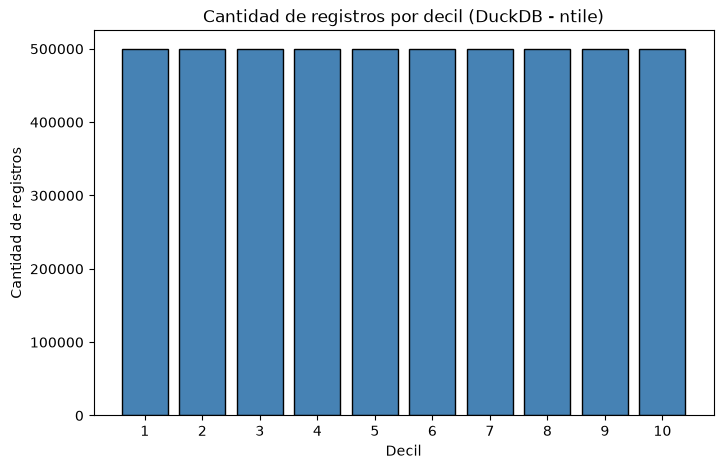

Gráfica guardada en ../resultados/graficos/duckdb_deciles.png


In [7]:
plt.figure(figsize=(8, 5))
plt.bar(deciles["decil"], deciles["cantidad"], color="steelblue", edgecolor="black")
plt.title("Cantidad de registros por decil (DuckDB - ntile)")
plt.xlabel("Decil")
plt.ylabel("Cantidad de registros")
plt.xticks(deciles["decil"])

plt.savefig("../resultados/graficos/duckdb_deciles.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfica guardada en ../resultados/graficos/duckdb_deciles.png")